# 02 · Feature Engineering
Three representations are compared under identical protocol:

| name | definition | dim |
|---|---|---|
| `pixels` | flattened intensities in [0,1] | 784 |
| `hog` | Histogram of Oriented Gradients (skimage) | 864 |
| `hog_stats` | HOG + 16 hand-crafted shape statistics | 880 |

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src.config import *
from src.data_loader import load_raw, to_unit, make_splits
from src.plotting import set_style
set_style()
def show(name, w=900): display(Image(filename=str(FIG_DIR / f'{name}.png'), width=w))
from src.features import *
S = make_splits()

## 1. Orientation check and scaling
Pixels are scaled to [0,1], labels untouched. Images are stored upright, so `skimage.feature.hog` is applied on the (row, col) array directly.

## 2. How HOG works
1. Compute horizontal/vertical gradients `gx, gy`.
2. Magnitude `sqrt(gx²+gy²)` and orientation `atan2(gy, gx)` per pixel.
3. Split the image into cells (4×4 px); each cell makes a histogram of orientations, weighted by magnitude.
4. Group 2×2 cells into overlapping blocks and L2-Hys normalise (illumination invariance).
5. Concatenate all block vectors.

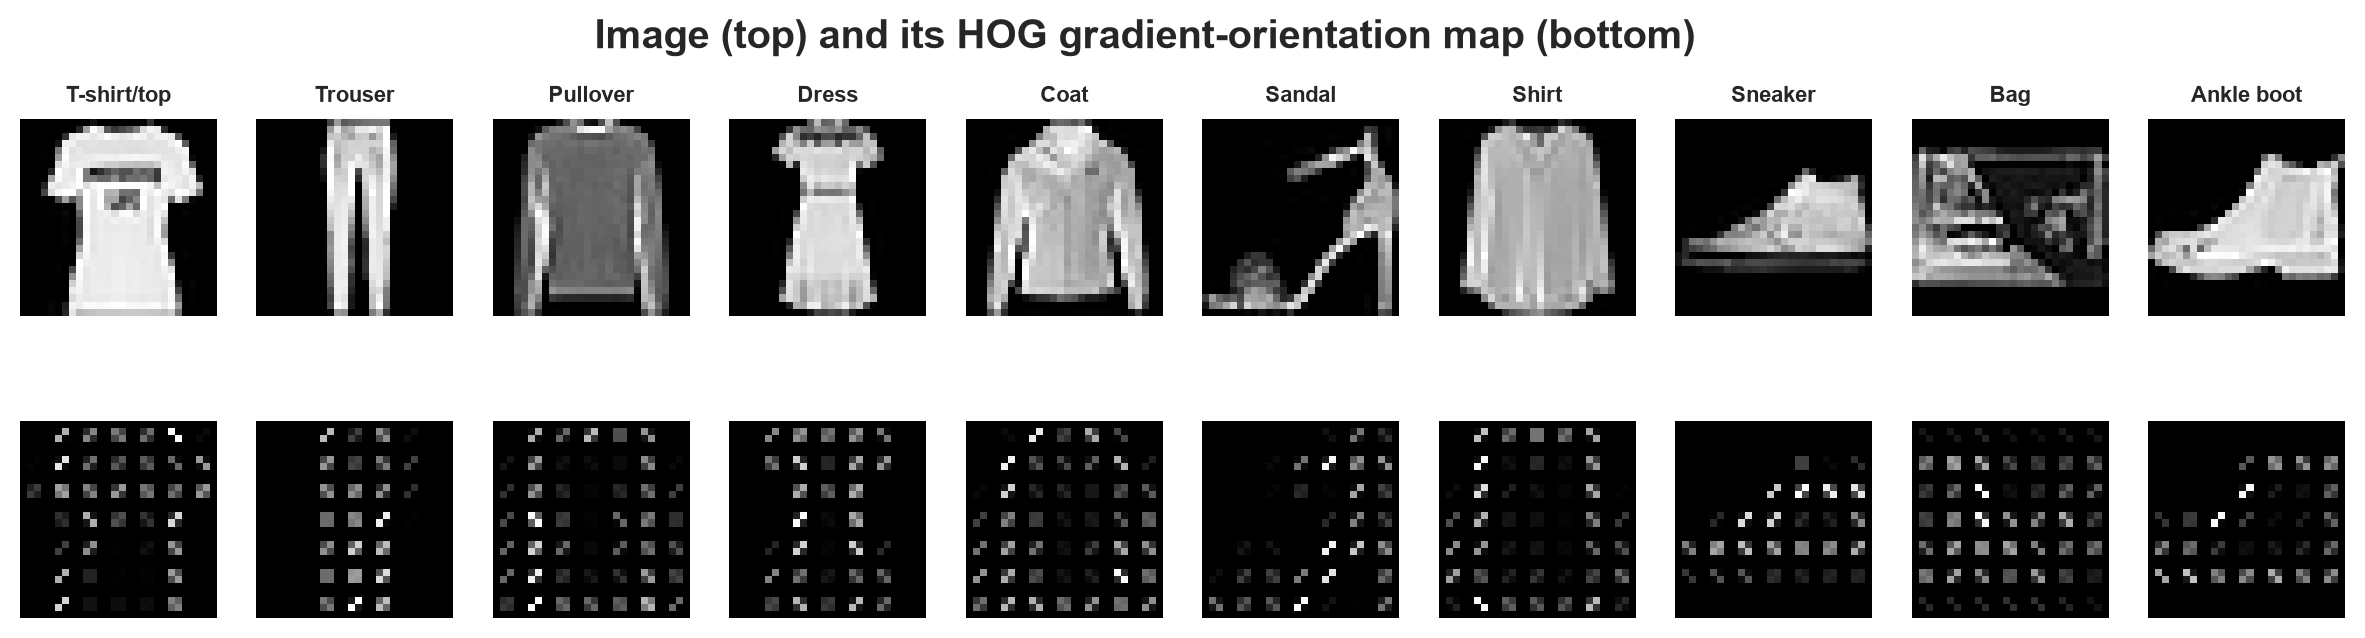

In [2]:
show('fe_02_hog_visual', 1000)

## 3. HOG hyper-parameter ablation
Grid: orientations {6,9,12} × cell {2,4,7} × block {1,2}; scored on validation with a Logistic-Regression probe (12k training images).

In [3]:
pd.read_csv(TABLE_DIR/'fe_hog_ablation.csv').head(12)

,orientations,pixels_per_cell,cells_per_block,dim,val_acc,feat_time_s
0,12,2x2,2x2,8112,0.870333,5.2
1,9,2x2,2x2,6084,0.865083,4.9
2,6,2x2,2x2,4056,0.858750,4.4
3,6,4x4,2x2,864,0.855833,1.3
4,12,2x2,1x1,2352,0.852167,4.2
5,12,4x4,2x2,1728,0.844333,1.4
6,9,4x4,2x2,1296,0.844250,1.4
7,9,2x2,1x1,1764,0.843333,4.1
8,9,7x7,2x2,324,0.838000,0.7
9,6,4x4,1x1,294,0.837083,1.4


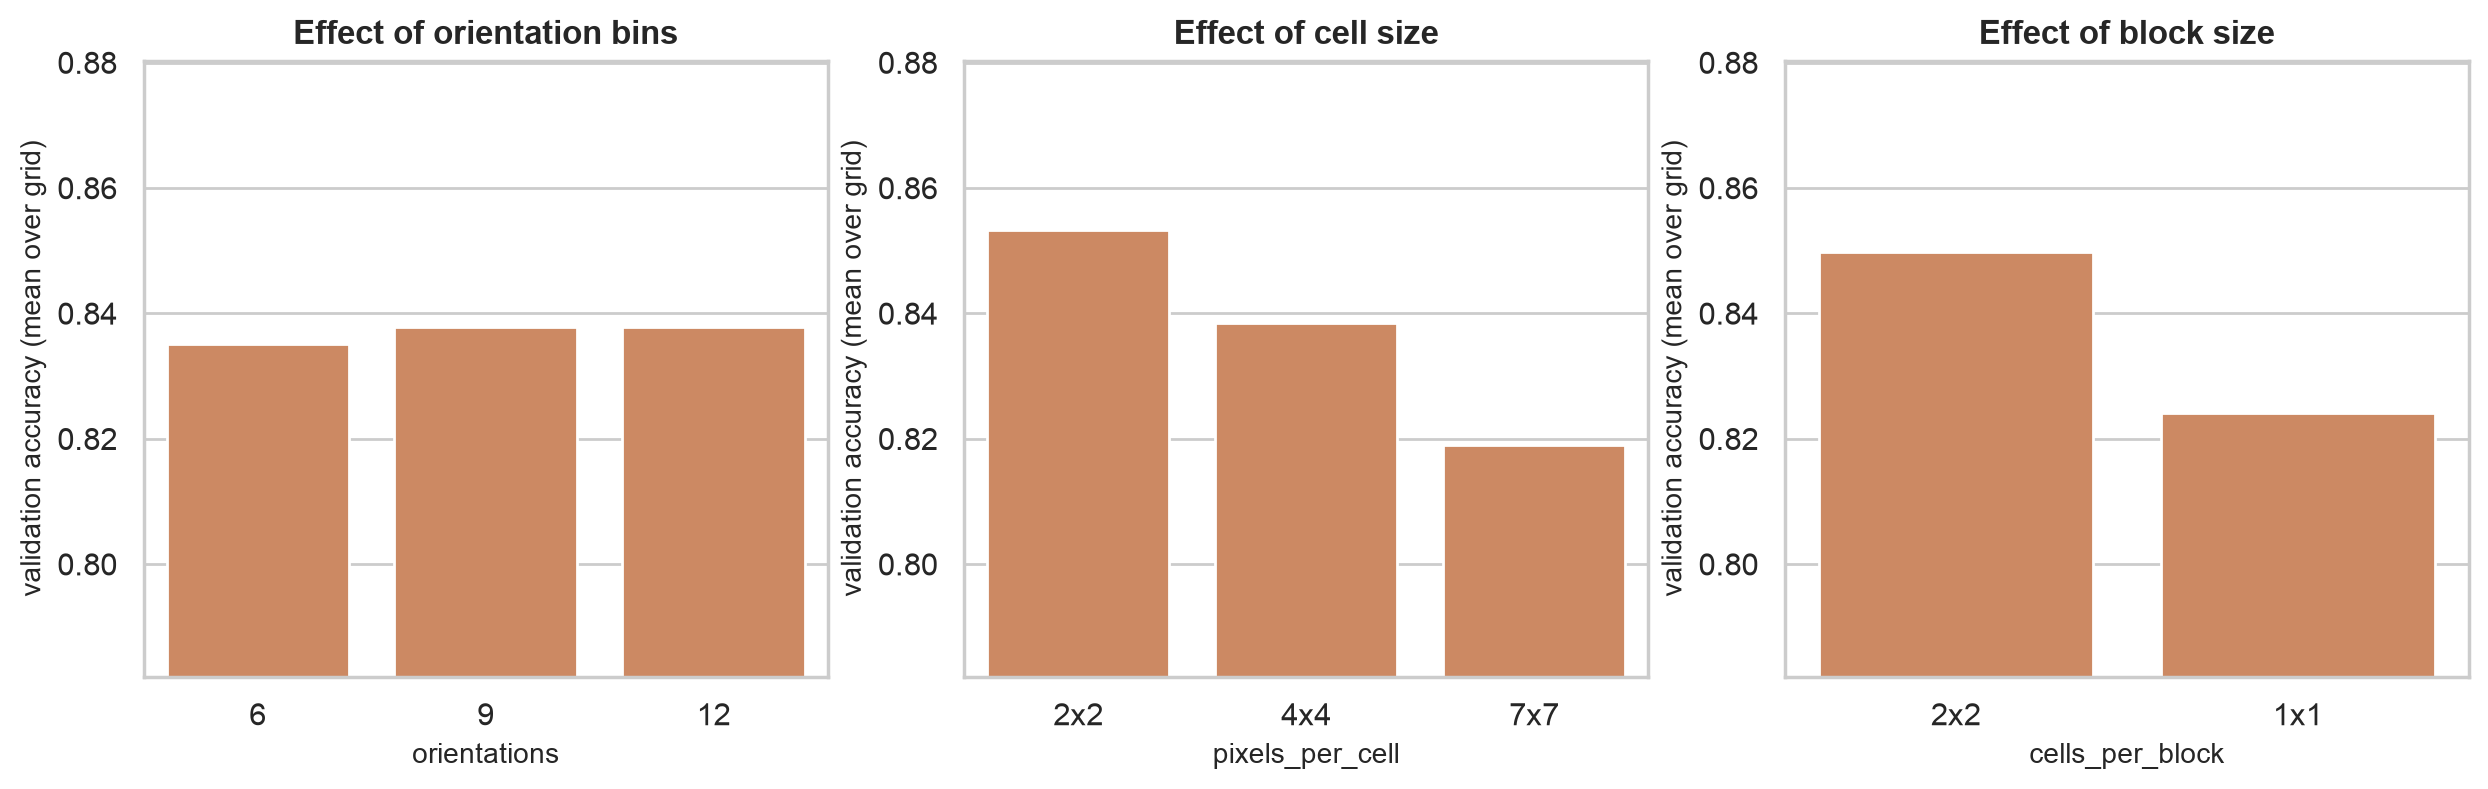

In [4]:
show('fe_01_hog_ablation', 1000)

**Decision:** finer cells improve accuracy but explode dimensionality (4k-8k) and slow kNN/SVM/RF. We choose the best configuration under a 2,000-d budget: **6 orientations, 4×4 cells, 2×2 blocks (864-d)**.

## 4. Hand-crafted shape statistics
16 interpretable global descriptors: intensity mean/std, ink fraction, bounding-box height/width/aspect, centroid, left-right and top-bottom symmetry, Sobel edge density, top/bottom mass, width of top/bottom rows and the gap between trouser legs.

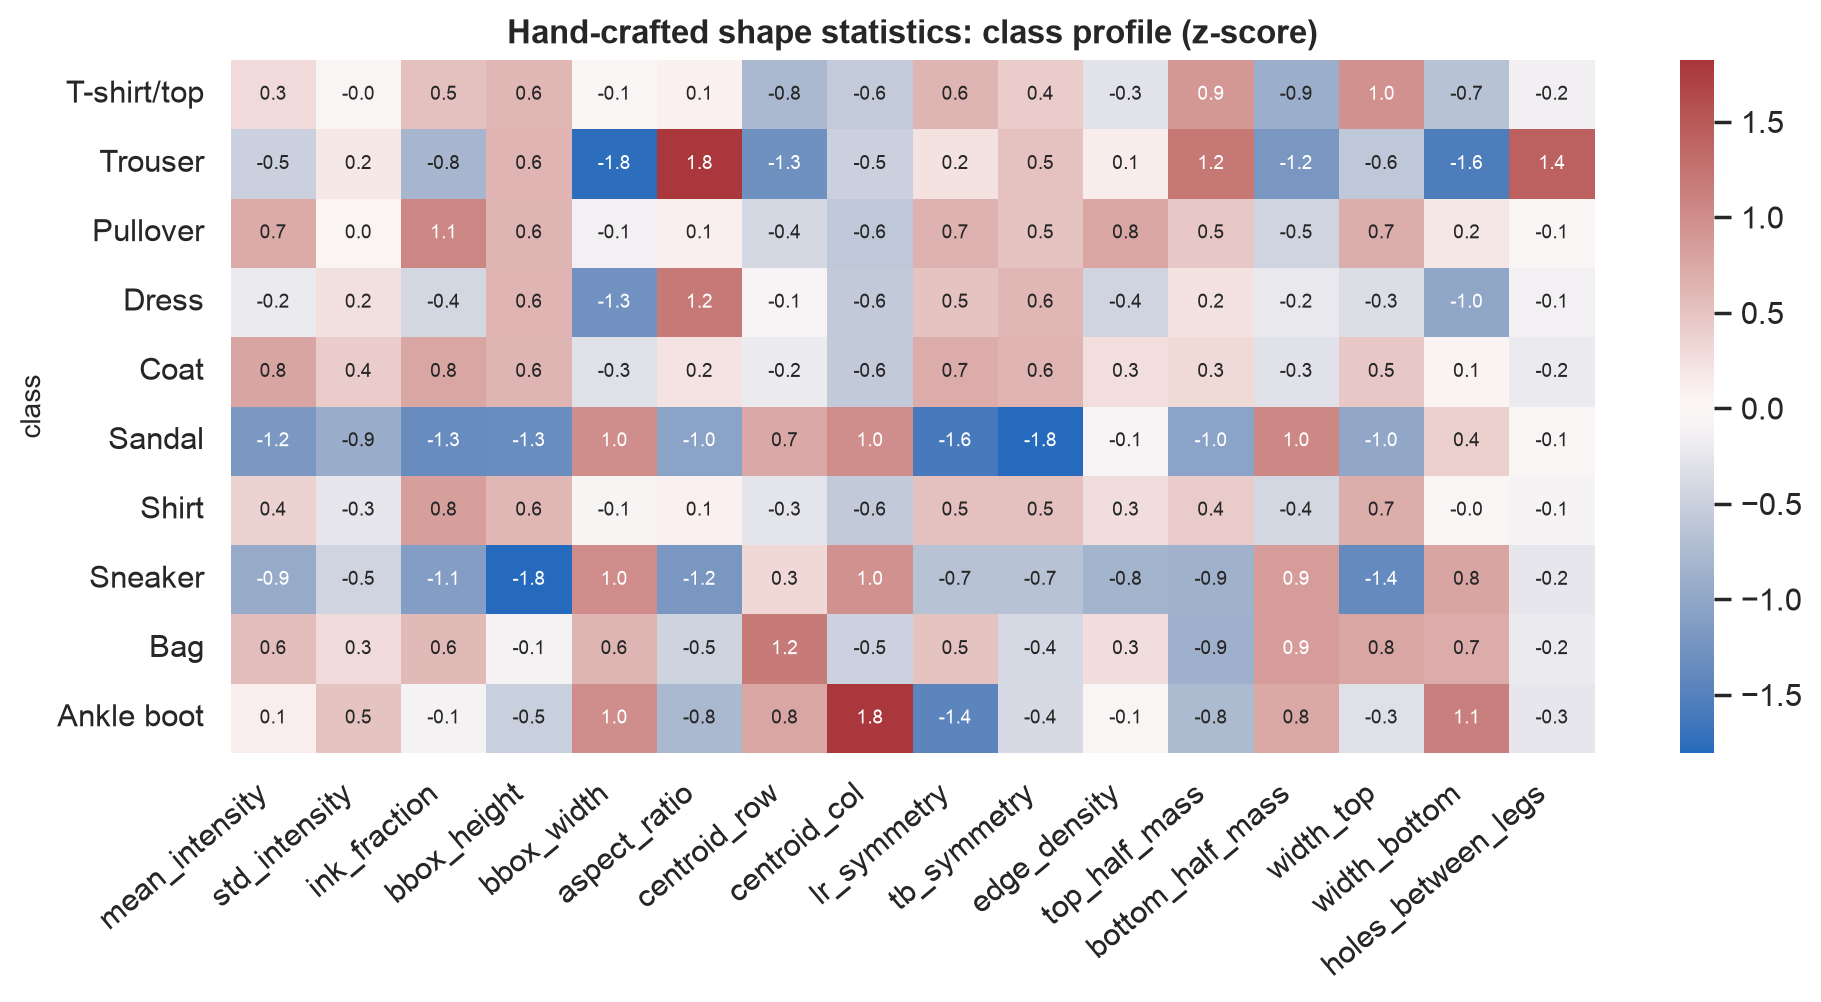

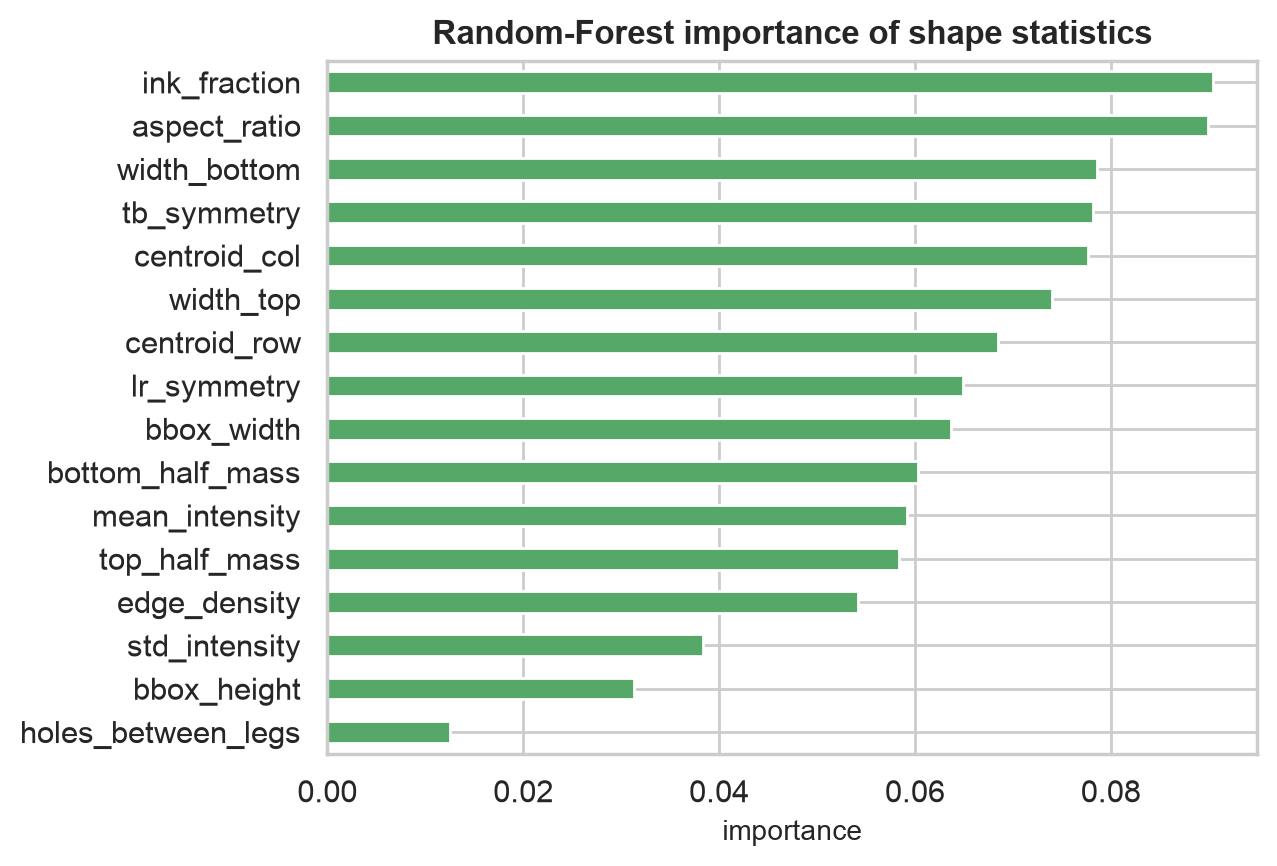

In [5]:
show('fe_03_shape_stats_profile', 900); show('fe_04_shape_stats_importance', 500)

## 5. PCA on pixels (reference compression)

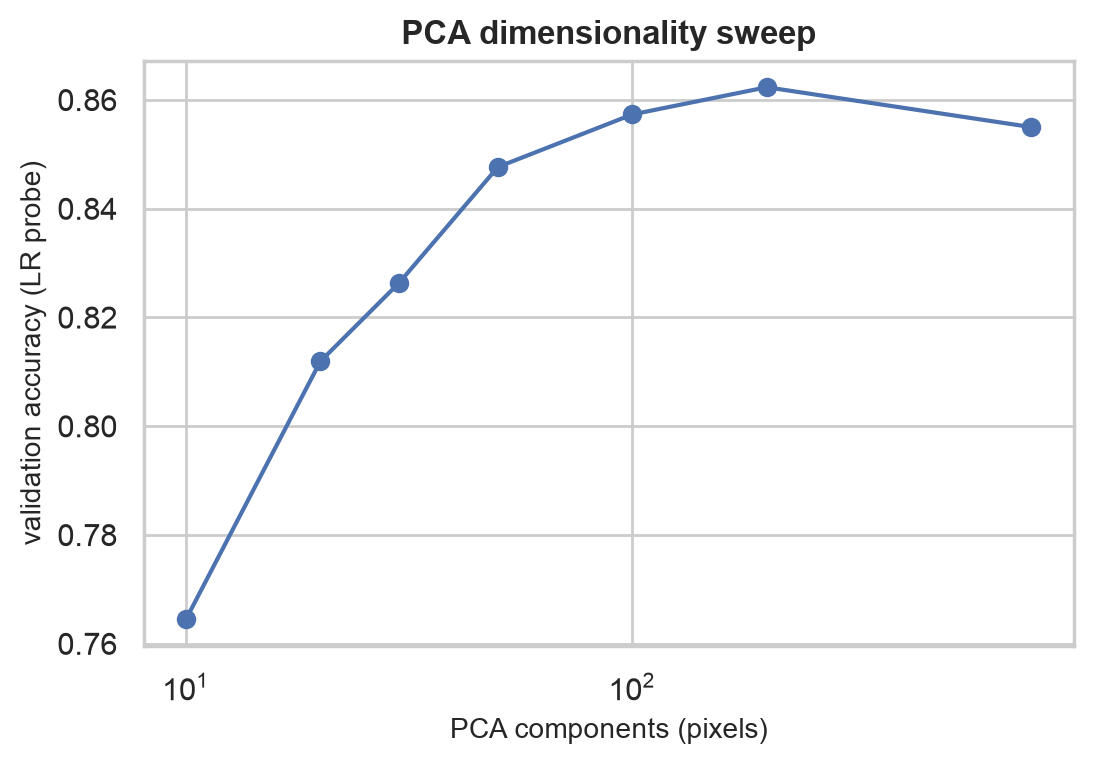

,n_components,val_acc
0,10,0.764500
1,20,0.811917
2,30,0.826333
3,50,0.847667
4,100,0.857333
5,200,0.862333
6,784,0.855000


In [6]:
show('fe_05_pca_sweep', 520); pd.read_csv(TABLE_DIR/'fe_pca_sweep.csv')

## 6. Feature-set comparison (same LR probe)

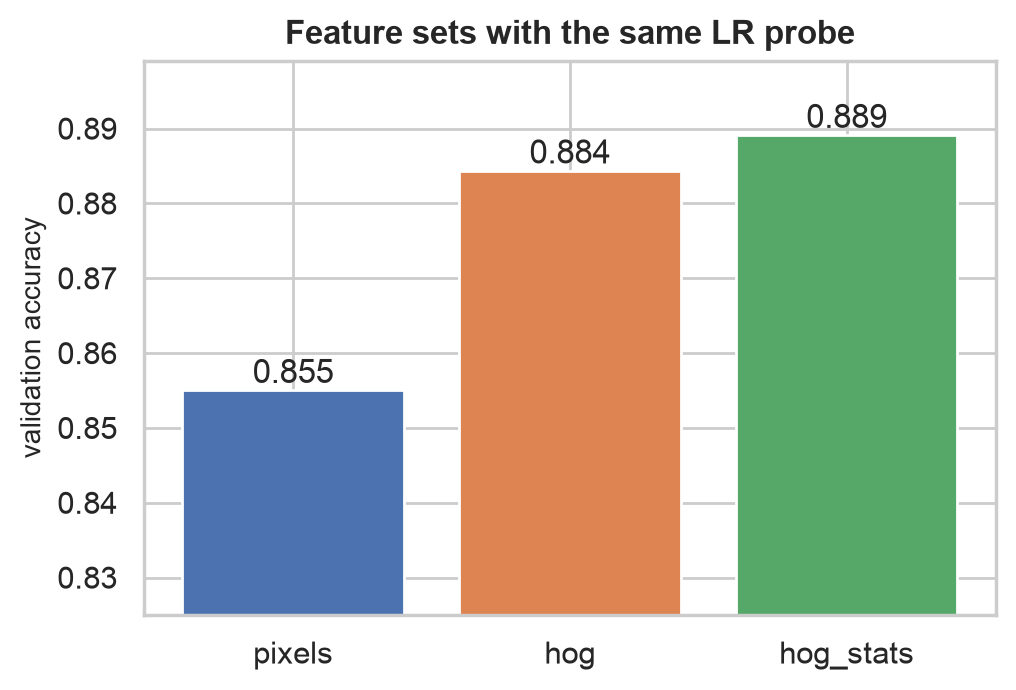

,feature_set,dim,val_acc,fit_s
0,pixels,784,0.855000,4.9
1,hog,864,0.884333,4.3
2,hog_stats,880,0.889083,5.3


In [7]:
show('fe_06_feature_set_probe', 520); pd.read_csv(TABLE_DIR/'fe_feature_set_probe.csv')

The probe is deliberately simple; the full 4-model comparison is in notebook 03.